# 05 · Meta de composição (D20)

**Pergunta:** alguma composição vence mais do que deveria?

Dois problemas tornam o win rate bruto inútil:

1. **Força do time.** Composição "forte" é a que os times fortes jogam, e eles venceriam de qualquer
   jeito. A medida é o desempenho **acima do esperado pelo Elo**: vitórias − probabilidade de vencer
   o mapa (a do Elo é por série; `map_probability` converte).
2. **Amostra pequena.** Uma comp com 3 jogos e 3 vitórias não é a melhor do jogo. **Shrinkage
   empírico** (normal–normal): cada comp é puxada para zero na proporção da própria incerteza, com a
   variância real entre comps estimada dos dados, por mapa × patch.

Patch: o recorte é a versão maior (12.x, 13.x). Por patch exato a amostra não sustenta (tabela
abaixo) — a contingência do documento mestre prevê cair para só mapa; a versão maior fica no meio.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
raw = A.table(con, "mart_compositions")
per_patch = raw.groupby(["map_name", "patch", "composition_key"]).size()
per_major = raw.assign(major=raw.patch.str.split(".").str[0]).groupby(
    ["map_name", "major", "composition_key"]).size()
pd.DataFrame({
    "recorte": ["mapa × patch exato", "mapa × versão maior"],
    "grupos (comp)": [len(per_patch), len(per_major)],
    "mediana de mapas por comp": [per_patch.median(), per_major.median()],
    "comps com ≥ 10 mapas": [(per_patch >= 10).sum(), (per_major >= 10).sum()],
})

,recorte,grupos (comp),mediana de mapas por comp,comps com ≥ 10 mapas
0,mapa × patch exato,4404,1.0,213
1,mapa × versão maior,2224,2.0,250


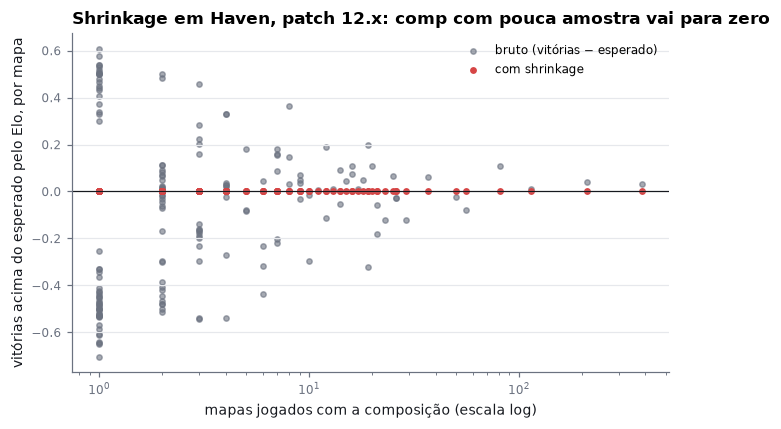

In [3]:
comps = A.compositions(con, min_maps=1)
big = comps.groupby(["map_name", "patch_major"]).maps.sum().idxmax()
g = comps[(comps.map_name == big[0]) & (comps.patch_major == big[1])]
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(g.maps, g.excess, s=12, color=P.MUTED, alpha=0.6, label="bruto (vitórias − esperado)")
ax.scatter(g.maps, g.shrunk, s=12, color=P.ATTACK, label="com shrinkage")
ax.axhline(0, color=P.INK, lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("mapas jogados com a composição (escala log)")
ax.set_ylabel("vitórias acima do esperado pelo Elo, por mapa")
ax.set_title(f"Shrinkage em {big[0]}, patch {big[1]}.x: comp com pouca amostra vai para zero")
ax.legend()
plt.show()

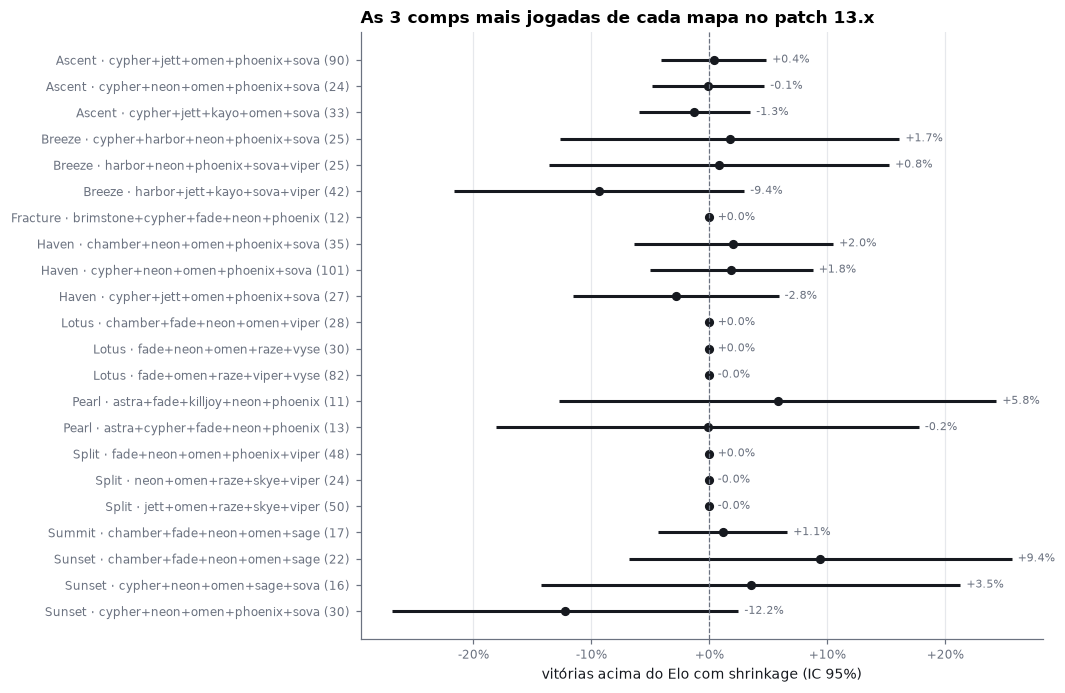

In [4]:
current = comps[comps.patch_major == comps.patch_major.max()]
top = (current[current.maps >= 10].sort_values("maps", ascending=False)
       .groupby("map_name").head(3).sort_values(["map_name", "shrunk"], ascending=[True, False]))
fig, ax = plt.subplots(figsize=(8, 0.28 * len(top) + 1))
P.forest(ax, [f"{r.map_name} · {r.composition_key} ({r.maps})" for r in top.itertuples()],
         top.shrunk, top.low, top.high, null=0.0, fmt="{:+.1%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_xlabel("vitórias acima do Elo com shrinkage (IC 95%)")
ax.set_title(f"As 3 comps mais jogadas de cada mapa no patch {comps.patch_major.max()}.x")
plt.show()

## Conclusão

In [5]:
tested = comps[comps.maps >= 5]
pos = tested[tested.low > 0]
neg = tested[tested.high < 0]
best = tested.loc[tested.shrunk.idxmax()]
display(Markdown(f"""
- {len(tested)} combinações comp × mapa × versão com ao menos 5 mapas.
- Depois do controle por força do time e do shrinkage, **{len(pos)}** ficam com IC inteiro acima de
  zero e **{len(neg)}** abaixo.
- Maior estimativa: {best.composition_key} em {best.map_name} ({best.patch_major}.x), com
  {fmt(best.win_rate * 100, 0)}% de vitória bruta em {best.maps} mapas, mas
  {fmt(best.shrunk * 100, 1)} p.p. acima do Elo depois do shrinkage
  (IC {fmt(best.low * 100, 1)} a {fmt(best.high * 100, 1)}).
- {"**Inconclusivo:** nenhuma composição se distingue do esperado pela força de quem a joga. O meta "
   "se mede pela popularidade (notebook 08), não por vantagem de desempenho detectável na janela."
   if len(pos) + len(neg) == 0 else
   "As comps com IC fora de zero são as candidatas a vantagem real; as demais, inconclusivas."}
"""))


- 541 combinações comp × mapa × versão com ao menos 5 mapas.
- Depois do controle por força do time e do shrinkage, **0** ficam com IC inteiro acima de
  zero e **0** abaixo.
- Maior estimativa: cypher+omen+sova+waylay+yoru em Sunset (13.x), com
  100% de vitória bruta em 8 mapas, mas
  14,7 p.p. acima do Elo depois do shrinkage
  (IC -6,0 a 35,4).
- **Inconclusivo:** nenhuma composição se distingue do esperado pela força de quem a joga. O meta se mede pela popularidade (notebook 08), não por vantagem de desempenho detectável na janela.
